Predicted probability after F2: 0.4057
Predicted class: 0


C:\Users\kumarni\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


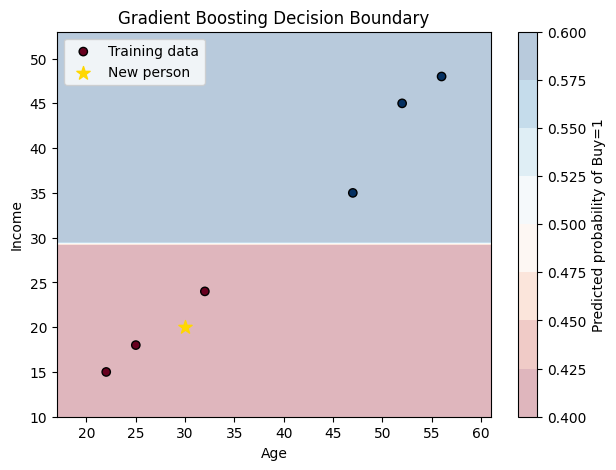

'Output -\nPredicted probability after F2: 0.4057\nPredicted class: 0\n'

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
import numpy as np
import matplotlib.pyplot as plt
# Dataset
data = {
   'Age':    [22, 25, 47, 52, 32, 56],
   'Income': [15, 18, 35, 45, 24, 48],
   'Buy':    [0, 0, 1, 1, 0, 1]
}
df = pd.DataFrame(data)
X = df[['Age', 'Income']]
y = df['Buy']
# Two boosting rounds
model = GradientBoostingClassifier(n_estimators=2, learning_rate=0.1, max_depth=1, random_state=0)
model.fit(X, y)
# Predict new person
new_person = pd.DataFrame({'Age': [30], 'Income': [20]})
prob = model.predict_proba(new_person)[0][1]
pred = model.predict(new_person)[0]
print(f"Predicted probability after F2: {prob:.4f}")
print("Predicted class:", pred)
# Plot decision boundary
x_min, x_max = X['Age'].min() - 5, X['Age'].max() + 5
y_min, y_max = X['Income'].min() - 5, X['Income'].max() + 5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                    np.linspace(y_min, y_max, 100))
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
Z = Z.reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
plt.colorbar(label='Predicted probability of Buy=1')
plt.scatter(X['Age'], X['Income'], c=y, edgecolor='k', cmap='RdBu', label='Training data')
plt.scatter(new_person['Age'], new_person['Income'], c='gold', s=100, marker='*', label='New person')
plt.xlabel('Age')
plt.ylabel('Income')
plt.title('Gradient Boosting Decision Boundary')
plt.legend()
plt.show()
'''Output -
Predicted probability after F2: 0.4057
Predicted class: 0
'''